# IDEF 2022/2023: limpeza e preparação dos dados
**Pergunta do projeto:** em que gastam as famílias portuguesas o seu dinheiro, e como difere isso entre regiões e níveis de rendimento?

**Quadros usados** (Inquérito às Despesas das Famílias 2022/2023, dados definitivos, INE):
- `Q.2.1.a` / `Q.2.1.b`: despesa média anual em € e em % do total, por região (NUTS II)
- `Q.2.11.a` / `Q.2.11.b`: o mesmo, por quintil de rendimento equivalente

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = Path("../data/IDF20222023_a.xlsx")
OUT_DIR = Path("../data/processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_colwidth", 70)

In [2]:
from pathlib import Path
print(Path.cwd())
print(DATA_PATH.resolve(), DATA_PATH.exists())

/Users/weo/dev/project/notebooks
/Users/weo/dev/project/data/IDF20222023_a.xlsx True


## 1. Como estão os dados originais?
Cada folha do Excel tem o título na primeira linha, os nomes das colunas só na linha 4, e **uma coluna extra a seguir a cada valor** com sinais convencionais do INE:
- `x` no lugar do valor: dado não disponível
- `§` na coluna ao lado: estimativa pouco fiável (coeficiente de variação elevado)

A coluna `COICOP` tem uma hierarquia: `01` (grupo), `01.1`, `01.1.1`... (subníveis). Somar tudo contaria as mesmas despesas várias vezes.

In [3]:
bruto = pd.read_excel(DATA_PATH, sheet_name="Q.2.1.b", header=None, dtype=object)
bruto.iloc[:10, :8]

,0,1,2,3,4,5,6,7
0,Q.2.1.b. Estrutura da despesa total anual média (%) por agregado s...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,COICOP,NaN,Portugal,NaN,Continente,NaN,Norte,NaN
4,NaN,Despesa total anual média por agregado,100,NaN,100,NaN,100,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,01,Produtos alimentares e bebidas não alcoólicas,12.9,NaN,13,NaN,13.8,NaN
7,01.1,Produtos alimentares,12,NaN,12,NaN,12.9,NaN
8,01.1.1,Cereais e produtos à base de cereais,1.8,NaN,1.7,NaN,1.9,NaN
9,01.1.1.1,Cereais,0.1,NaN,0.1,NaN,0.2,NaN


## 2. Função de carregamento
Transforma qualquer quadro "a/b" para formato longo (uma linha por categoria × grupo), com:
- `valor` numérico (os `x` passam a `NaN`, **não a zero**)
- `baixa_fiabilidade` verdadeiro quando o INE marca `§`
- `nivel` da hierarquia COICOP (0 = total, 1 = grupo de topo, 2, 3, 4 = subníveis)

In [4]:
def carregar_quadro(path, folha):
    """Lê uma folha do IDEF e devolve-a em formato longo e arrumado."""
    raw = pd.read_excel(path, sheet_name=folha, header=None, dtype=object)

    # A linha de cabeçalho é a que tem 'COICOP' na primeira coluna
    h = raw.index[raw.iloc[:, 0].astype(str).str.strip() == "COICOP"][0]
    cab = raw.iloc[h]

    # Colunas de valores: células de cabeçalho preenchidas a partir da 3.ª coluna
    cols_val = [
        i for i in range(2, raw.shape[1])
        if pd.notna(cab[i]) and str(cab[i]).strip() not in ("", "Índice")
    ]

    corpo = raw.iloc[h + 1:]
    corpo = corpo[corpo.iloc[:, 1].notna()]  # só linhas com descrição

    registos = []
    for _, lin in corpo.iterrows():
        cod = lin.iloc[0]
        desc = str(lin.iloc[1]).strip()
        for i in cols_val:
            flag = lin.iloc[i + 1] if i + 1 < raw.shape[1] else None
            registos.append({
                "coicop": "TOTAL" if pd.isna(cod) else str(cod).strip(),
                "descricao": desc,
                "grupo": " ".join(str(cab[i]).split()),   # limpa quebras de linha
                "valor": pd.to_numeric(lin.iloc[i], errors="coerce"),  # 'x' -> NaN
                "baixa_fiabilidade": str(flag).strip() == "§",
            })

    df = pd.DataFrame(registos)
    df["nivel"] = np.where(df["coicop"] == "TOTAL", 0, df["coicop"].str.count(r"\.") + 1)
    return df

In [5]:
regiao_eur = carregar_quadro(DATA_PATH, "Q.2.1.a")
regiao_pct = carregar_quadro(DATA_PATH, "Q.2.1.b")
quintil_eur = carregar_quadro(DATA_PATH, "Q.2.11.a")
quintil_pct = carregar_quadro(DATA_PATH, "Q.2.11.b")

In [6]:
regiao_pct.head(18)

,coicop,descricao,grupo,valor,baixa_fiabilidade,nivel
0,TOTAL,Despesa total anual média por agregado,Portugal,100.0,False,0
1,TOTAL,Despesa total anual média por agregado,Continente,100.0,False,0
2,TOTAL,Despesa total anual média por agregado,Norte,100.0,False,0
3,TOTAL,Despesa total anual média por agregado,Centro,100.0,False,0
4,TOTAL,Despesa total anual média por agregado,A.M. Lisboa,100.0,False,0
5,TOTAL,Despesa total anual média por agregado,Alentejo,100.0,False,0
6,TOTAL,Despesa total anual média por agregado,Algarve,100.0,False,0
7,TOTAL,Despesa total anual média por agregado,R.A. Açores,100.0,False,0
8,TOTAL,Despesa total anual média por agregado,R.A. Madeira,100.0,False,0
9,01,Produtos alimentares e bebidas não alcoólicas,Portugal,12.9,False,1


## 3. Validações
Antes de confiar nos dados, confirmo que batem certo com o que o INE publicou e que as percentagens somam 100.

In [7]:
# 3.1 Os grupos de topo (nível 1) devem somar ~100% em cada região
def somas(pct):
    topo = pct[pct.nivel == 1]
    return pd.DataFrame({
        "soma_%": topo.groupby("grupo")["valor"].sum().round(1),
        "em_falta": topo.groupby("grupo")["valor"].apply(lambda x: x.isna().sum()),
    })

s_reg, s_qui = somas(regiao_pct), somas(quintil_pct)
display(s_reg)
display(s_qui)

# Onde não falta nenhum valor, a soma tem de ser ~100 (desvio por arredondamento)
for s in (s_reg, s_qui):
    ok = s[s.em_falta == 0]
    assert (ok["soma_%"].sub(100).abs() < 0.5).all()

,soma_%,em_falta
grupo,,
A.M. Lisboa,100.0,0
Alentejo,98.9,1
Algarve,99.9,0
Centro,100.2,0
Continente,100.0,0
Norte,100.0,0
Portugal,100.0,0
R.A. Açores,100.1,0
R.A. Madeira,100.2,0


,soma_%,em_falta
grupo,,
1º quintil,100.0,0
2º quintil,100.0,0
3º quintil,99.9,0
4º quintil,99.9,0
5º quintil,99.8,0
Total,100.0,0


**O que isto mostra:** a soma não dá exatamente 100 no **Alentejo (98,9%)**, e não é erro: no quadro original, o valor de *Serviços de educação* para o Alentejo vem como `x` (não disponível), por isso falta cerca de 1 ponto percentual. Nos restantes casos, os desvios de 0,1 a 0,2 são só arredondamentos. Esta é uma limitação a registar no README.

In [8]:
# 3.2 Os totais para Portugal devem coincidir com os publicados pelo INE
topo_pt = regiao_pct[(regiao_pct.nivel == 1) & (regiao_pct.grupo == "Portugal")].set_index("coicop")["valor"]
total_pt = regiao_eur[(regiao_eur.nivel == 0) & (regiao_eur.grupo == "Portugal")]["valor"].iloc[0]
print(f"Despesa média anual por agregado: {total_pt:,.0f} €")
print(f"Habitação (04): {topo_pt['04']}%   Alimentação (01): {topo_pt['01']}%   Transportes (07): {topo_pt['07']}%")

Despesa média anual por agregado: 23,900 €
Habitação (04): 39.3%   Alimentação (01): 12.9%   Transportes (07): 12.1%


In [9]:
# 3.3 Quantos valores em falta ('x') e pouco fiáveis ('§')?
for nome, df in [("região (€)", regiao_eur), ("quintil (€)", quintil_eur)]:
    topo = df[df.nivel <= 1]
    print(f"{nome}: nos grupos de topo há {topo.valor.isna().sum()} em falta e "
          f"{topo.baixa_fiabilidade.sum()} pouco fiáveis (em {len(topo)} valores)")
    print(f"   em todos os níveis: {df.valor.isna().mean():.0%} em falta, {df.baixa_fiabilidade.mean():.0%} pouco fiáveis")

região (€): nos grupos de topo há 1 em falta e 0 pouco fiáveis (em 126 valores)
   em todos os níveis: 29% em falta, 15% pouco fiáveis
quintil (€): nos grupos de topo há 0 em falta e 0 pouco fiáveis (em 84 valores)
   em todos os níveis: 22% em falta, 12% pouco fiáveis


**Decisão de limpeza:** mantenho os valores marcados com `§` mas guardo-os com a coluna `baixa_fiabilidade`, em vez de os apagar. Assim posso excluí-los ou destacá-los mais tarde. As análises principais usam só os **grupos de topo (nível 1)**, onde há praticamente só valores fiáveis; os níveis mais finos têm muito mais `x` e `§`.

## 4. Tabelas arrumadas para análise
Junto o valor em € e em % e guardo em CSV.

In [10]:
def juntar(eur, pct):
    chave = ["coicop", "descricao", "grupo", "nivel"]
    out = eur.rename(columns={"valor": "despesa_eur", "baixa_fiabilidade": "baixa_fiab_eur"}).merge(
        pct.rename(columns={"valor": "peso_pct", "baixa_fiabilidade": "baixa_fiab_pct"}),
        on=chave, how="outer")
    return out

por_regiao = juntar(regiao_eur, regiao_pct)
por_quintil = juntar(quintil_eur, quintil_pct)

por_regiao.to_csv(OUT_DIR / "despesa_por_regiao.csv", index=False)
por_quintil.to_csv(OUT_DIR / "despesa_por_quintil.csv", index=False)

por_regiao[por_regiao.nivel == 1].head(8)

,coicop,descricao,grupo,despesa_eur,baixa_fiab_eur,nivel,peso_pct,baixa_fiab_pct
0,01,Produtos alimentares e bebidas não alcoólicas,A.M. Lisboa,3000.0,False,1,11.2,False
1,01,Produtos alimentares e bebidas não alcoólicas,Alentejo,3206.0,False,1,15.0,False
2,01,Produtos alimentares e bebidas não alcoólicas,Algarve,3473.0,False,1,14.2,False
3,01,Produtos alimentares e bebidas não alcoólicas,Centro,3018.0,False,1,13.6,False
4,01,Produtos alimentares e bebidas não alcoólicas,Continente,3114.0,False,1,13.0,False
5,01,Produtos alimentares e bebidas não alcoólicas,Norte,3206.0,False,1,13.8,False
6,01,Produtos alimentares e bebidas não alcoólicas,Portugal,3091.0,False,1,12.9,False
7,01,Produtos alimentares e bebidas não alcoólicas,R.A. Açores,2556.0,False,1,13.2,False


## 5. Primeiros gráficos
Para confirmar que os dados contam uma história. A análise a sério fica para o notebook seguinte.

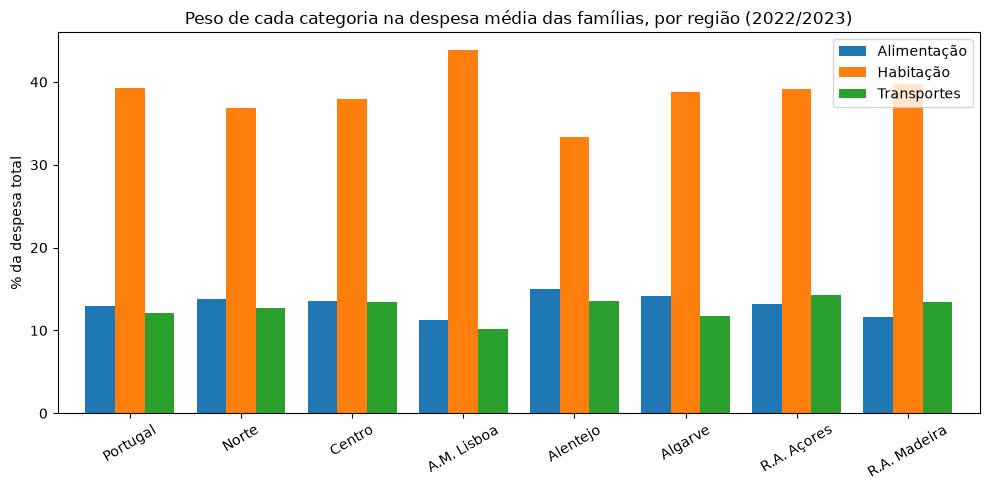

In [13]:
regioes = ["Norte", "Centro", "A.M. Lisboa", "Alentejo", "Algarve", "R.A. Açores", "R.A. Madeira"]
cats = {"01": "Alimentação", "04": "Habitação", "07": "Transportes"}

topo = por_regiao[(por_regiao.nivel == 1) & (por_regiao.coicop.isin(cats))]
tab = topo.pivot(index="grupo", columns="coicop", values="peso_pct").loc[["Portugal"] + regioes]
tab.columns = [cats[c] for c in tab.columns]

ax = tab.plot(kind="bar", figsize=(10, 5), width=0.8)
ax.set_title("Peso de cada categoria na despesa média das famílias, por região (2022/2023)")
ax.set_ylabel("% da despesa total")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

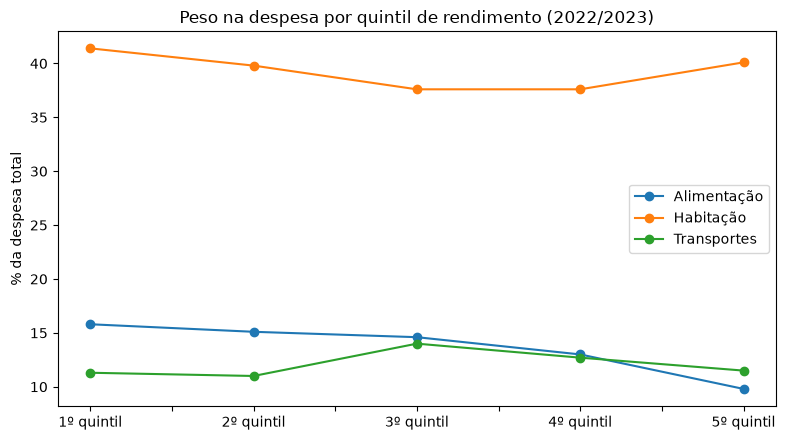

In [14]:
quintis = ["1º quintil", "2º quintil", "3º quintil", "4º quintil", "5º quintil"]
topo_q = por_quintil[(por_quintil.nivel == 1) & (por_quintil.coicop.isin(cats))]
tab_q = topo_q.pivot(index="grupo", columns="coicop", values="peso_pct").loc[quintis]
tab_q.columns = [cats[c] for c in tab_q.columns]

ax = tab_q.plot(marker="o", figsize=(8, 4.5))
ax.set_title("Peso na despesa por quintil de rendimento (2022/2023)")
ax.set_ylabel("% da despesa total")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

## Próximos passos
- Notebook 2: análise exploratória (todas as categorias de topo, comparação entre regiões e quintis)
- Responder a algumas perguntas com SQL (carregar os CSV de `data/processed/` numa base SQLite)
- Escolher 3 a 5 gráficos para o dashboard e escrever as conclusões no README